# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Лопатін Володимир'
LIST_NUMBER = 12
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print(STUDENT_NAME, 'ШІ-31; варіант', VARIANT)

Лопатін Володимир ШІ-31; варіант 12


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.metadata
for p in ['pandas','numpy','scikit-learn','matplotlib','shap']:
    print(p, importlib.metadata.version(p))

pandas 3.1.1
numpy 2.5.4
scikit-learn 1.9.1
matplotlib 3.11.2
shap 0.54.1


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
TYPE_OF_TASK = 'класифікація' # Два можливі результати: відтік або збереження договору.
METRIC = 'AUC' # Ранжування ризиків без порога; accuracy приховує дисбаланс класів.
CV_SCHEME = 'стратифікована 5-кратна, 4 повтори' # Зберігає частки класів; 20 однакових поділів для парних порівнянь.
print(TYPE_OF_TASK, METRIC, CV_SCHEME)

класифікація AUC стратифікована 5-кратна, 4 повтори


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.249

типи стовпців: {'str': 13, 'float64': 8, 'int64': 5}


In [6]:
audit=pd.DataFrame({'тип':raw.dtypes.astype(str),'унікальних':raw.nunique(),'% пропусків':100*raw.isna().mean(),'приклад':[str(raw[c].dropna().iloc[0]) for c in raw]})
display(audit.sort_values('% пропусків',ascending=False))
print('Точність завжди 0:',1-raw[TARGET].mean())
print('Текстових колонок:',sum(raw.dtypes=='object'))

,тип,унікальних,% пропусків,приклад
сума_повернення_депозиту,float64,299,75.083333,408.09
дата_розірвання,str,254,75.083333,2024-12-15
середній_час_відповіді_хв,float64,266,32.416667,32.1
трафік_ГБ,str,956,5.000000,51.9
щомісячний_платіж,str,1131,4.000000,288.66
аварій_на_ділянці_за_квартал,float64,6,3.000000,1.0
стать,str,6,0.000000,Ч
місто,str,6,0.000000,Золочів
id_клієнта,str,1200,0.000000,K120000
вік,float64,63,0.000000,35.0


Точність завжди 0: 0.7508333333333334
Текстових колонок: 0


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
for c,pattern in [('щомісячний_платіж','грн'),('трафік_ГБ','1900')]:
    print(c,raw.loc[raw[c].astype(str).str.contains(pattern),c].head().tolist())
display(pd.crosstab(raw['середній_час_відповіді_хв'].isna(),raw['кількість_звернень_у_підтримку']))

щомісячний_платіж ['374.97 грн', '261.44 грн', '326.48 грн', '281.24 грн', '226.84 грн']
трафік_ГБ ['1900-01-05 00:00:00', '1900-01-22 00:00:00', '1900-01-23 00:00:00']


кількість_звернень_у_підтримку,0,1,2,3,4,5
середній_час_відповіді_хв,,,,,,
False,0,442,238,95,27,9
True,389,0,0,0,0,0


In [8]:
PROBLEM_TEXT_IN_NUMBER='щомісячний_платіж'
PROBLEM_EXCEL_DATE='трафік_ГБ'
PROBLEM_MNAR='середній_час_відповіді_хв'
MNAR_MEANING='За відсутності звернень немає часу відповіді: пропуск означає, що підтримка не обслуговувала звернення; це структурна відсутність вимірювання, а не нуль хвилин.'
print(MNAR_MEANING)

За відсутності звернень немає часу відповіді: пропуск означає, що підтримка не обслуговувала звернення; це структурна відсутність вимірювання, а не нуль хвилин.


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
def to_number(s):
    def one(v):
        if pd.isna(v) or isinstance(v,(datetime.date,datetime.datetime,pd.Timestamp)):
            return np.nan
        if isinstance(v,(int,float,np.number)): return float(v)
        v=str(v).strip()
        if re.search(r'\b\d{4}-\d{2}-\d{2}\b|\b\d{1,2}[./]\d{1,2}[./]\d{4}\b',v): return np.nan
        m=re.search(r'[-+]?\d+(?:[.,]\d+)?',v.replace('\u00a0',''))
        return float(m.group().replace(',','.')) if m else np.nan
    return s.map(one)
_r=to_number(pd.Series([1,'350.5 грн','2,75',datetime.datetime(1900,1,11),None,'немає','1900-01-11 00:00:00']))
assert np.allclose(_r[:3],[1,350.5,2.75]) and _r[3:].isna().all()
print('Перевірки to_number пройдено')

Перевірки to_number пройдено


In [10]:
DROP_ALWAYS=['id_клієнта']
CAT=['стать','місто','філія','тариф','тип_підключення','спосіб_оплати','автоплатіж','код_тарифного_плану']
# Типи задані за семантикою, без оцінки порогів на повній вибірці.
def build_X(d,drop):
    X=pd.DataFrame(index=d.index); log=[]
    for c in d:
        if c in drop or c==TARGET:
            log.append({'стовпець':c,'рішення':'вилучено'}); continue
        if c in ['дата_підключення','дата_розірвання']:
            X[c]=(pd.to_datetime(d[c],errors='coerce')-pd.Timestamp('1970-01-01')).dt.total_seconds()/86400
        elif c in CAT:
            s=d[c].astype('string').str.strip().str.lower()
            if c=='стать':s=s.replace({'чол':'ч','жін':'ж'})
            X[c]=s.astype('category')
        else:X[c]=to_number(d[c])
        log.append({'стовпець':c,'рішення':str(X[c].dtype)})
    return X,pd.DataFrame(log)
X_all,log=build_X(raw,DROP_ALWAYS); y=raw[TARGET].astype(int)
display(log)

,стовпець,рішення
0,id_клієнта,вилучено
1,вік,float64
2,стать,category
3,місто,category
4,філія,category
5,тариф,category
6,тип_підключення,category
7,спосіб_оплати,category
8,автоплатіж,category
9,кількість_послуг,float64


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
from sklearn.base import clone
def make_pipe(X,clf):
    cat=X.select_dtypes(include=['category','object','string']).columns.tolist()
    num=[c for c in X if c not in cat]
    prep=ColumnTransformer([
        ('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),
        ('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cat)])
    return Pipeline([('prep',prep),('clf',clone(clf))])
def logreg():return LogisticRegression(max_iter=3000,random_state=SEED)
cv=list(RepeatedStratifiedKFold(n_splits=5,n_repeats=4,random_state=SEED).split(X_all,y))
print('20 фіксованих поділів; усі fit обробки всередині Pipeline')

20 фіксованих поділів; усі fit обробки всередині Pipeline

---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.968 ± 0.013
час      : 0.7 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION=f'AUC {auc_naive.mean():.4f} підозріло висока: у CRM є інформація після відтоку, тому першою перевіряю витік.'
print(FIRST_REACTION)

AUC 0.9677 підозріло висока: у CRM є інформація після відтоку, тому першою перевіряю витік.


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d,y,min_group=20):
    rows=[]
    for c in d:
        if c==TARGET:continue
        m=d[c].notna()
        if min(m.sum(),(~m).sum())<min_group:continue
        a=roc_auc_score(y,m.astype(int))
        rows.append({'ознака':c,'заповнено':int(m.sum()),'частка_відтоку_де_заповнено':y[m].mean(),'частка_відтоку_де_пропуск':y[~m].mean(),'показник':max(a,1-a)})
    return pd.DataFrame(rows).sort_values('показник',ascending=False)
scan=leak_scan(raw,y);display(scan)

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
4,дата_розірвання,299,1.000000,0.000000,1.000000
5,сума_повернення_депозиту,299,1.000000,0.000000,1.000000
3,середній_час_відповіді_хв,811,0.274969,0.195373,0.546606
1,трафік_ГБ,1140,0.247368,0.283333,0.504566
0,щомісячний_платіж,1152,0.248264,0.270833,0.502316
2,аварій_на_ділянці_за_квартал,1164,0.250000,0.222222,0.502160


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK=['дата_розірвання','сума_повернення_депозиту']
TARGET_WHY={'дата_розірвання':'Фіксується при розірванні, договір уже припиняється.','сума_повернення_депозиту':'Обчислюється під час закриття договору, після прогнозованої події.'}
print(TARGET_WHY)

{'дата_розірвання': 'Фіксується при розірванні, договір уже припиняється.', 'сума_повернення_депозиту': 'Обчислюється під час закриття договору, після прогнозованої події.'}


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.968 ± 0.012


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
print(list(X2.columns))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'річний_платіж', 'код_тарифного_плану', 'скоринг_партнера', 'дата_підключення', 'оцінка_ризику_менеджером']


In [18]:
HUMAN_LEAK=['оцінка_ризику_менеджером']
HUMAN_LEAK_WHY='Менеджер оцінив клієнта після спостереження подальшої поведінки; поле заповнене для всіх, тому детектор заповненості не має двох груп і не перевіряє часову доступність.'
X3,_=build_X(raw,DROP_ALWAYS+TARGET_LEAK+HUMAN_LEAK)
auc3=cross_val_score(make_pipe(X3,logreg()),X3,y,cv=cv,scoring='roc_auc')
print(HUMAN_LEAK_WHY);print('AUC',auc3.mean(),auc3.std())

Менеджер оцінив клієнта після спостереження подальшої поведінки; поле заповнене для всіх, тому детектор заповненості не має двох груп і не перевіряє часову доступність.
AUC 0.8261998076009336 0.0297426253743109


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

,mean,size
філія,,
Ф-01 Центр,0.413146,213
Ф-02 Захід,0.378238,193
Ф-03 Схід,0.161765,204
Ф-04 Південь,0.159204,201
Ф-05 Північ,0.172589,197
Ф-06 Приміська,0.203125,192


,mean,size
дата_підключення,,
2023Q1,0.248062,129
2023Q2,0.228571,140
2023Q3,0.260870,161
2023Q4,0.280702,171
2024Q1,0.230263,152
2024Q2,0.259740,154
2024Q3,0.175182,137
2024Q4,0.294872,156


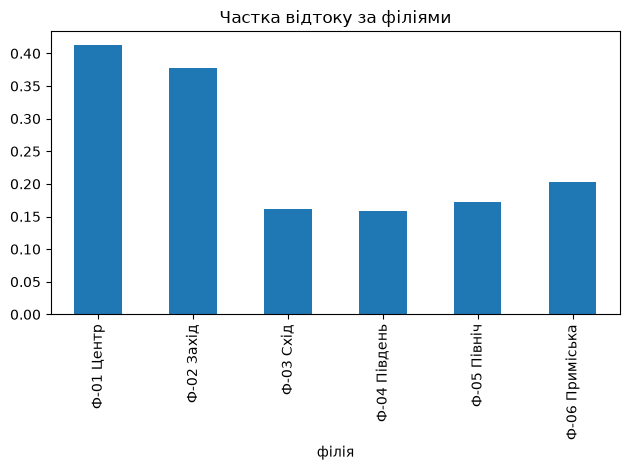

In [19]:
branch=raw.groupby('філія')[TARGET].agg(['mean','size']);display(branch)
quarter=raw.groupby(pd.to_datetime(raw['дата_підключення']).dt.to_period('Q'))[TARGET].agg(['mean','size']);display(quarter)
branch['mean'].plot.bar(title='Частка відтоку за філіями');plt.tight_layout();plt.show()

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT='філія'
source=raw['філія'].isin(['Ф-01 Центр','Ф-02 Захід']).astype(int)
X4,_=build_X(raw,DROP_ALWAYS+TARGET_LEAK+HUMAN_LEAK+[SUSPECT])
src_cv=list(RepeatedStratifiedKFold(n_splits=5,n_repeats=4,random_state=SEED).split(X4,source))
auc_src=cross_val_score(make_pipe(X4,logreg()),X4,source,cv=src_cv,scoring='roc_auc')
auc4=cross_val_score(make_pipe(X4,logreg()),X4,y,cv=cv,scoring='roc_auc')
print('Джерело:',auc_src.mean(),auc_src.std(),'Відтік:',auc4.mean(),auc4.std())
print('Висока AUC джерела є діагностичним сигналом, а не доказом причинності; вилучення філії не гарантує усунення її проксі.')

Джерело: 0.7141221897064038 0.0230150322006462 Відтік: 0.7849894618375282 0.03882647153678095
Висока AUC джерела є діагностичним сигналом, а не доказом причинності; вилучення філії не гарантує усунення її проксі.


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.968
2. мінус цільовий витік,22,0.968
3. мінус оцінки людини,21,0.826
4. мінус артефакт збору,20,0.785


чесне число: 0.785 ± 0.039


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
DECISION_ARTEFACT='викинути'
DECISION_WHY='Потрібен переносимий прогноз: у перших двох філіях частка відтоку стрибком вища. Вилучення філії послаблює прямий артефакт, але потрібна зовнішня перевірка за філіями та часом, бо проксі можуть залишитися.'
print(DECISION_WHY)

Потрібен переносимий прогноз: у перших двох філіях частка відтоку стрибком вища. Вилучення філії послаблює прямий артефакт, але потрібна зовнішня перевірка за філіями та часом, бо проксі можуть залишитися.


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [23]:
from sklearn.tree import DecisionTreeClassifier
MODELS={'логістична регресія':logreg(),'одне дерево':DecisionTreeClassifier(max_depth=6,min_samples_leaf=15,random_state=SEED),'випадковий ліс':RandomForestClassifier(n_estimators=200,random_state=SEED,n_jobs=-1),'гістограмний бустинг':HistGradientBoostingClassifier(max_iter=150,max_leaf_nodes=15,l2_regularization=1,random_state=SEED)}
scores={}; times={}; rows=[]
for name,clf in MODELS.items():
    t0=time.perf_counter();a=cross_val_score(make_pipe(X4,clf),X4,y,cv=cv,scoring='roc_auc')
    times[name]=time.perf_counter()-t0;scores[name]=a
    rows.append({'модель':name,'AUC':a.mean(),'±':a.std(),'с за 20 навчань':times[name],'с на 100 навчань (екстраполяція)':times[name]*5})
cmp_models=pd.DataFrame(rows).set_index('модель');display(cmp_models)

,AUC,±,с за 20 навчань,с на 100 навчань (екстраполяція)
модель,,,,
логістична регресія,0.784989,0.038826,0.673978,3.369890
одне дерево,0.729878,0.030013,0.523708,2.618542
випадковий ліс,0.789223,0.031652,7.245608,36.228039
гістограмний бустинг,0.794412,0.025746,6.133655,30.668276


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [24]:
from scipy.stats import t
def paired(a,b):
    # Поправка Nadeau–Bengio: залежні повторні згортки, test/train=1/4.
    d=np.asarray(b)-np.asarray(a)
    return float(d.mean()),float(t.ppf(.975,len(d)-1)*d.std(ddof=1)*np.sqrt(1/len(d)+1/4))
base=scores['логістична регресія']
for name in MODELS:
    print(name,paired(base,scores[name]))
print('Інтервали наближені, з поправкою на залежність 20 згорток; це не 20 незалежних експериментів.')

логістична регресія (0.0, 0.0)
одне дерево (-0.05511114232502005, 0.037350002973909585)
випадковий ліс (0.004233803015957227, 0.035323577876126167)
гістограмний бустинг (0.009422882136279903, 0.03904737079740038)
Інтервали наближені, з поправкою на залежність 20 згорток; це не 20 незалежних експериментів.


In [25]:
CHOSEN_MODEL='випадковий ліс'
CHOSEN_WHY='Компроміс якості, розкиду та часу з таблиці; підтримує нелінійність, взаємодії, вбудовану важливість і TreeSHAP. Логістична простіша для пояснення, тому порівнюємо її поліпшення окремо.'
print(CHOSEN_MODEL,CHOSEN_WHY)

випадковий ліс Компроміс якості, розкиду та часу з таблиці; підтримує нелінійність, взаємодії, вбудовану важливість і TreeSHAP. Логістична простіша для пояснення, тому порівнюємо її поліпшення окремо.


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [26]:
def add_features(X):
    F=X.copy()
    # Ціна одиниці швидкості: можлива незадоволеність співвідношенням ціни та якості.
    F['ціна_Мбіт']=F['щомісячний_платіж']/F['швидкість_тарифу_Мбіт'].clip(lower=1)
    # Витрати відносно користування: можливий низький суб'єктивний зиск.
    F['трафік_на_гривню']=F['трафік_ГБ']/F['щомісячний_платіж'].clip(lower=1)
    # Інтенсивність проблем відносно тривалості відносин.
    F['звернення_на_місяць']=F['кількість_звернень_у_підтримку']/F['місяців_обслуговування'].clip(lower=1)
    return F
X5=add_features(X4);print('Ознак:',X4.shape[1],X5.shape[1])

Ознак: 20 23


In [27]:
t0=time.perf_counter();auc5=cross_val_score(make_pipe(X5,logreg()),X5,y,cv=cv,scoring='roc_auc');feature_time=time.perf_counter()-t0
print('Нові ознаки:',auc5.mean(),auc5.std(),'Приріст та 95% півширина:',paired(base,auc5),'секунд:',feature_time)

Нові ознаки: 0.7838317787072586 0.0374476684109701 Приріст та 95% півширина: (-0.0011576831302695322, 0.004398276456206892) секунд: 0.6747479999999086


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [28]:
FEATURES_VS_MODEL=f'Ліс дав більший середній приріст: {paired(base,scores[CHOSEN_MODEL])[0]:+.4f} ± {paired(base,scores[CHOSEN_MODEL])[1]:.4f} проти {paired(base,auc5)[0]:+.4f} ± {paired(base,auc5)[1]:.4f} для нових ознак (95% парні інтервали). Обидва інтервали включають нуль, перевага не підтверджена. Час 20 навчань: {times[CHOSEN_MODEL]:.2f} с і {feature_time:.2f} с відповідно.'
print(FEATURES_VS_MODEL)

Ліс дав більший середній приріст: +0.0042 ± 0.0353 проти −0.0012 ± 0.0044 для трьох нових ознак (95% парні інтервали). Обидва інтервали включають нуль, перевага не підтверджена. Час 20 навчань: 7.25 с для лісу проти 0.67 с для логістичної регресії з новими ознаками.


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [29]:
# Для пояснень лишаємо вихідні чесні ознаки: синтетичні відношення інакше спотворюють PDP при незалежній підстановці чисельника.
FINAL_X=X4
FINAL_CLF=RandomForestClassifier(n_estimators=300,random_state=SEED,n_jobs=-1)
Xtr,Xte,ytr,yte=train_test_split(FINAL_X,y,test_size=.3,stratify=y,random_state=SEED)
model=make_pipe(FINAL_X,FINAL_CLF).fit(Xtr,ytr)
auc_hold=roc_auc_score(yte,model.predict_proba(Xte)[:,1]);print('Описова AUC відкладеної частини:',auc_hold)
print('Поділ уже використовувався в дослідницькому аналізі CV: це не незалежне підтвердження обраної моделі.')

Описова AUC відкладеної частини: 0.7920781893004115
Поділ уже використовувався в дослідницькому аналізі CV: це не незалежне підтвердження обраної моделі.


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

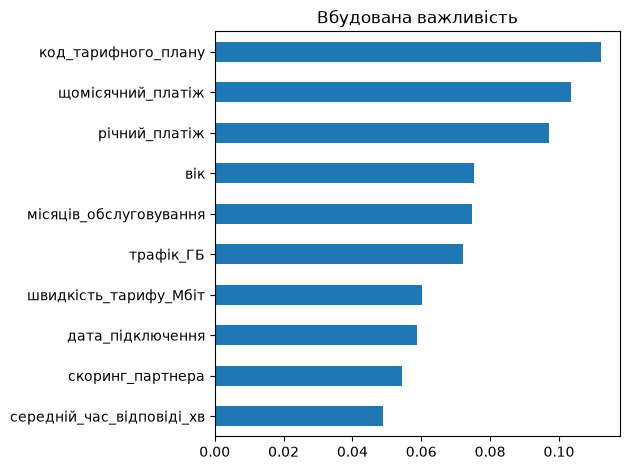

In [30]:
prep=model.named_steps['prep'];imp=model.named_steps['clf'].feature_importances_
mapping=[]
for name,trans,cols in prep.transformers_:
    if name=='num':mapping.extend(cols)
    elif name=='cat':
        for c,cats in zip(cols,trans.named_steps['onehot'].categories_):mapping.extend([c]*len(cats))
gini_imp=pd.Series(imp,index=mapping).groupby(level=0).sum().sort_values(ascending=False)
gini_imp.head(10).sort_values().plot.barh(title='Вбудована важливість');plt.tight_layout();plt.show()

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [31]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.037025
місяців_обслуговування,0.030350
трафік_ГБ,0.028193
річний_платіж,0.020434
щомісячний_платіж,0.016228
кількість_звернень_у_підтримку,0.009508
середній_час_відповіді_хв,0.006198
швидкість_тарифу_Мбіт,0.006187
знижка_відсоток,0.002280
аварій_на_ділянці_за_квартал,0.001724


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [32]:
importance=pd.DataFrame({'вбудована':gini_imp,'перестановочна':perm_imp}).sort_values('вбудована',ascending=False)
display(importance)

,вбудована,перестановочна
код_тарифного_плану,0.112122,-0.007605
щомісячний_платіж,0.103491,0.016228
річний_платіж,0.097095,0.020434
вік,0.075418,0.037025
місяців_обслуговування,0.074850,0.030350
трафік_ГБ,0.072064,0.028193
швидкість_тарифу_Мбіт,0.060083,0.006187
дата_підключення,0.058656,-0.001321
скоринг_партнера,0.054498,-0.005362
середній_час_відповіді_хв,0.048983,0.006198


In [33]:
FAKE_IMPORTANT='код_тарифного_плану'
FAKE_IMPORTANT_WHY='Категорія з 40 рівнями дає багато можливостей випадкового розбиття; після підсумовування дамі-стовпців навчальні покращення накопичуються; перевіряємо ранг і перестановочну важливість на відкладених рядках.'
print(FAKE_IMPORTANT_WHY);print('Ранг:',list(gini_imp.index).index(FAKE_IMPORTANT)+1);display(importance.loc[[FAKE_IMPORTANT]])

Категорія з 40 рівнями дає багато можливостей випадкового розбиття; після підсумовування дамі-стовпців навчальні покращення накопичуються; перевіряємо ранг і перестановочну важливість на відкладених рядках.
Ранг: 1


,вбудована,перестановочна
код_тарифного_плану,0.112122,-0.007605


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [34]:
corr=FINAL_X.select_dtypes('number').corr()
display(corr.where(np.triu(np.ones(corr.shape),1).astype(bool)).stack().loc[lambda s:s.abs()>.97])

щомісячний_платіж  річний_платіж    0.999201
dtype: float64

In [35]:
DUP_PAIR=['щомісячний_платіж','річний_платіж']
print('Кореляція:',corr.loc[DUP_PAIR[0],DUP_PAIR[1]])
print('До:',perm_imp.loc[DUP_PAIR].to_dict())
reduced=FINAL_X.drop(columns=DUP_PAIR[1]);mr=make_pipe(reduced,FINAL_CLF).fit(Xtr.drop(columns=DUP_PAIR[1]),ytr)
pr=permutation_importance(mr,Xte.drop(columns=DUP_PAIR[1]),yte,n_repeats=10,random_state=SEED,scoring='roc_auc')
after=float(pr.importances_mean[list(reduced).index(DUP_PAIR[0])]);print('Без дубля:',after)

Кореляція: 0.9992009750788207
До: {'щомісячний_платіж': 0.016228395061728407, 'річний_платіж': 0.0204341563786008}


Без дубля: 0.060440329218107006


In [36]:
DUP_EXPLANATION=f'Щомісячний платіж: {perm_imp[DUP_PAIR[0]]:.4f} з дублем і {after:.4f} без нього. Річний: {perm_imp[DUP_PAIR[1]]:.4f}. Ознаки ділять інформацію; окреме перемішування не є видаленням і може створювати нереалістичні пари значень. Знак зміни перевіряємо за фактичним результатом, без гарантії зростання.'
print(DUP_EXPLANATION)

Щомісячний платіж: 0.0162 з дублем і 0.0604 без нього. Річний: 0.0204. Ознаки ділять інформацію; окреме перемішування не є видаленням і може створювати нереалістичні пари значень. Знак зміни перевіряємо за фактичним результатом, без гарантії зростання.


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

вік : PDP на 360 рядках із заповненою ознакою


місяців_обслуговування : PDP на 360 рядках із заповненою ознакою


трафік_ГБ : PDP на 335 рядках із заповненою ознакою


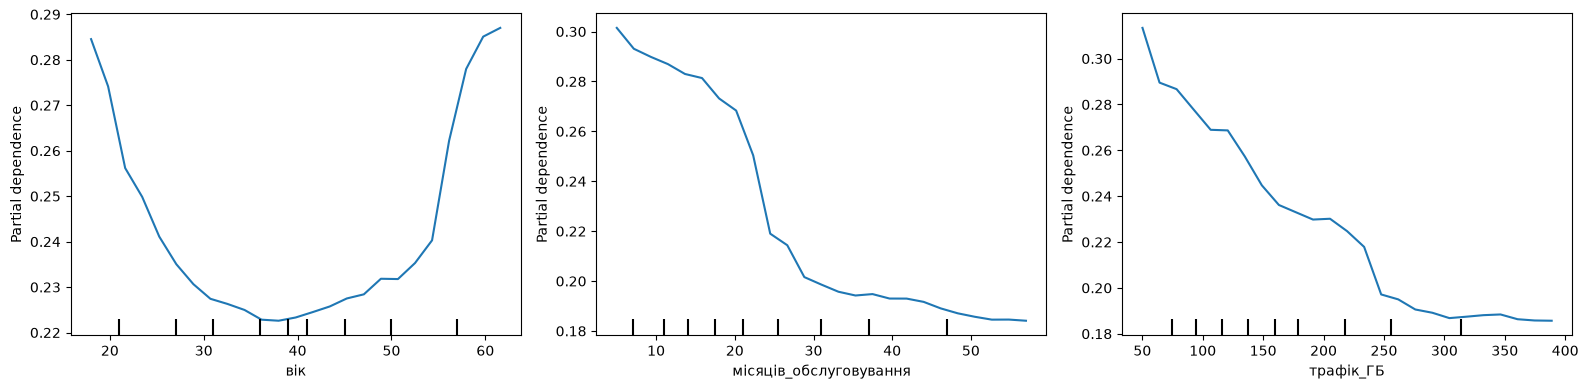

вік: прогноз від 0.285 до 0.287; мінімум 0.223 при 37.98, максимум 0.287. Це середній зв’язок серед клієнтів із виміряною ознакою, не ефект втручання.


місяців_обслуговування: прогноз від 0.301 до 0.184; мінімум 0.184 при 57.00, максимум 0.301. Це середній зв’язок серед клієнтів із виміряною ознакою, не ефект втручання.


трафік_ГБ: прогноз від 0.313 до 0.186; мінімум 0.186 при 388.82, максимум 0.313. Це середній зв’язок серед клієнтів із виміряною ознакою, не ефект втручання.


In [37]:
from sklearn.inspection import PartialDependenceDisplay
top_num=[c for c in perm_imp.index if c in FINAL_X.select_dtypes('number')][:3]
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,c in zip(axes,top_num):
    subset=Xte.loc[Xte[c].notna()]
    PartialDependenceDisplay.from_estimator(model,subset,[c],ax=ax,grid_resolution=25)
    print(c,': PDP на',len(subset),'рядках із заповненою ознакою')
plt.tight_layout();plt.show()
for c in top_num:
    sub=Xte.loc[Xte[c].notna()]
    p=partial_dependence(model,sub,[c],grid_resolution=25)
    grid=p['grid_values'][0];vals=p['average'][0]
    print(f'{c}: прогноз від {vals[0]:.3f} до {vals[-1]:.3f}; мінімум {vals.min():.3f} при {grid[np.argmin(vals)]:.2f}, максимум {vals.max():.3f}. Це середній зв’язок серед клієнтів із виміряною ознакою, не ефект втручання.')


### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

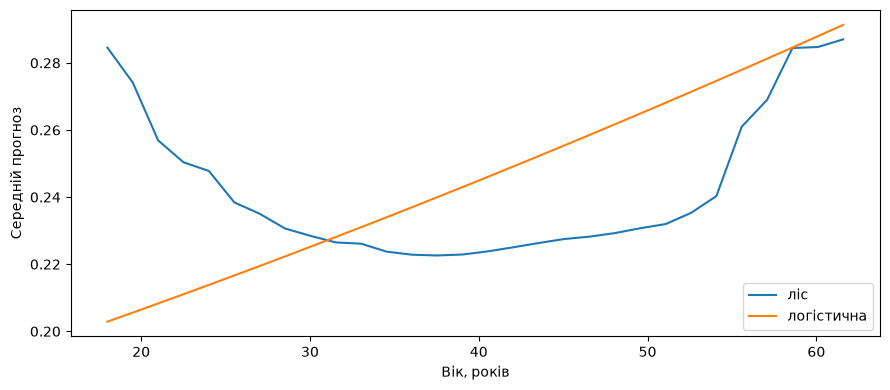

Мінімум PDP: 37.540344827586196


In [38]:
NONLINEAR_FEATURE='вік'
lr=make_pipe(FINAL_X,logreg()).fit(Xtr,ytr)
sub=Xte.loc[Xte[NONLINEAR_FEATURE].notna()]
fig,ax=plt.subplots(figsize=(9,4))
for est,label in [(model,'ліс'),(lr,'логістична')]:
    p=partial_dependence(est,sub,[NONLINEAR_FEATURE],grid_resolution=30)
    ax.plot(p['grid_values'][0],p['average'][0],label=label)
ax.set(xlabel='Вік, років',ylabel='Середній прогноз')
ax.legend();plt.tight_layout();plt.show()
pd_non=partial_dependence(model,sub,[NONLINEAR_FEATURE],grid_resolution=30)
quad_center=float(pd_non['grid_values'][0][np.argmin(pd_non['average'][0])]);print('Мінімум PDP:',quad_center)

In [39]:
NONLINEAR_MEANING='У молодших та старших клієнтів вищий ризик відтоку, ніж у середньому віці; це немонотонний зв’язок, який одна лінійна вікова ознака не відтворює.'
NONLINEAR_FIX='Квадрат відхилення віку від віку мінімального ризику на PDP.'
print(NONLINEAR_MEANING,NONLINEAR_FIX)

У молодших та старших клієнтів вищий ризик відтоку, ніж у середньому віці; це немонотонний зв’язок, який одна лінійна вікова ознака не відтворює. Квадрат відхилення віку від віку мінімального ризику на PDP.


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [40]:
# Мінімум знайдено дослідницьки на тих самих даних: цей приріст позначаємо як оптимістичний, не підтверджувальний.
Xq=X4.copy();Xq['квадрат_віку']=(Xq[NONLINEAR_FEATURE]-quad_center)**2
aq=cross_val_score(make_pipe(Xq,logreg()),Xq,y,cv=cv,scoring='roc_auc')
quad_diff=paired(base,aq);print('AUC з квадратом:',aq.mean(),aq.std(),'приріст:',quad_diff)

AUC з квадратом: 0.8158090450104567 0.029840511433632897 приріст: (0.030819583172928506, 0.020143054360192942)


In [41]:
QUAD_GAIN=quad_diff[0]
print('Дослідницький приріст:',QUAD_GAIN)

Дослідницький приріст: 0.030819583172928506


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

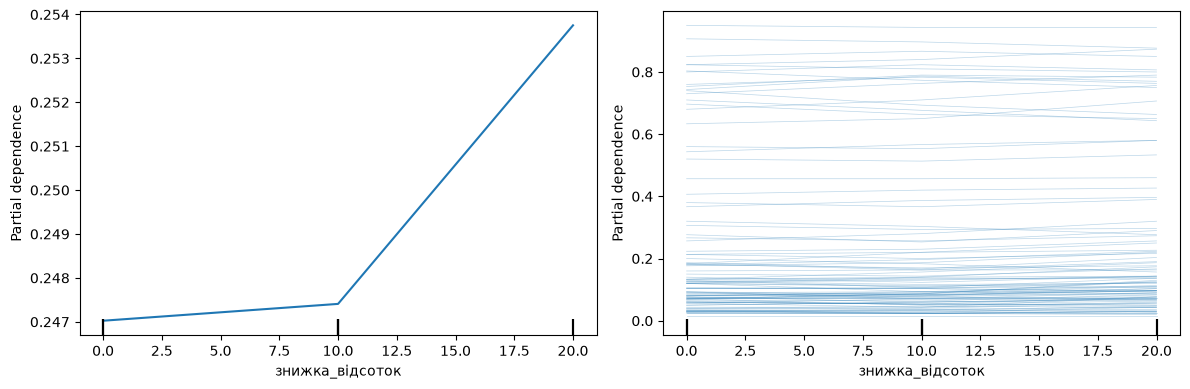

In [42]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
PartialDependenceDisplay.from_estimator(model,FINAL_X,['знижка_відсоток'],kind='average',ax=axes[0])
PartialDependenceDisplay.from_estimator(model,FINAL_X,['знижка_відсоток'],kind='individual',subsample=100,random_state=SEED,ax=axes[1])
plt.tight_layout();plt.show()

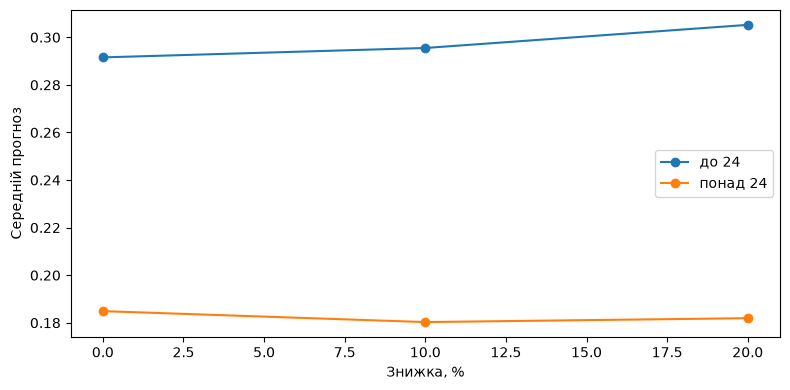

{'до 24': [0.2915546018121125, 0.2955126371006199, 0.30523128278493084], 'понад 24': [0.184896872920825, 0.18029274783765803, 0.18192947438456422]}


In [43]:
fig,ax=plt.subplots(figsize=(8,4));discount_curves={}
for label,mask in [('до 24',FINAL_X['місяців_обслуговування']<=24),('понад 24',FINAL_X['місяців_обслуговування']>24)]:
    p=partial_dependence(model,FINAL_X.loc[mask],['знижка_відсоток'])
    discount_curves[label]=p['average'][0].tolist()
    ax.plot(p['grid_values'][0],p['average'][0],marker='o',label=label)
ax.legend();ax.set(xlabel='Знижка, %',ylabel='Середній прогноз');plt.tight_layout();plt.show()
print(discount_curves)

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [44]:
empirical=raw.assign(група=np.where(raw['місяців_обслуговування']<=24,'до 24','понад 24')).groupby(['група','знижка_відсоток'])[TARGET].agg(['mean','size'])
display(empirical)

mean  size
група    знижка_відсоток                
до 24    0                0.278388   273
         10               0.314159   226
         20               0.370000   200
понад 24 0                0.214660   191
         10               0.147929   169
         20               0.085106   141

In [45]:
INTERACTION_FOUND='У нових клієнтів (до 24 місяців) емпіричний відтік зростає з 27.84% без знижки до 37.00% зі знижкою 20%; у давніх — спадає з 21.47% до 8.51%. PDP лісу відтворює ці напрями слабше: 0.2916→0.3052 та 0.1849→0.1819; у давніх крива не строго монотонна. Середній PDP приховує різні напрями ICE. Варто окремо тестувати знижки для давніх клієнтів та інші пропозиції для нових; спостережуваний зв’язок не доводить ефекту знижки, тому рішення перевіряється A/B-тестом.'
BUSINESS_ACTION='Окремий рандомізований тест пропозицій за стажем.'
print(INTERACTION_FOUND,BUSINESS_ACTION)

У нових клієнтів (до 24 місяців) емпіричний відтік зростає з 27.84% без знижки до 37.00% зі знижкою 20%; у давніх — спадає з 21.47% до 8.51%. PDP лісу відтворює ці напрями слабше: 0.2916→0.3052 та 0.1849→0.1819; у давніх крива не строго монотонна. Середній PDP приховує різні напрями ICE. Варто окремо тестувати знижки для давніх клієнтів та інші пропозиції для нових; спостережуваний зв’язок не доводить ефекту знижки, тому рішення перевіряється A/B-тестом.
Окремий рандомізований тест пропозицій за стажем.


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [46]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = Xte_t.shape[0]      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (360, 73)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

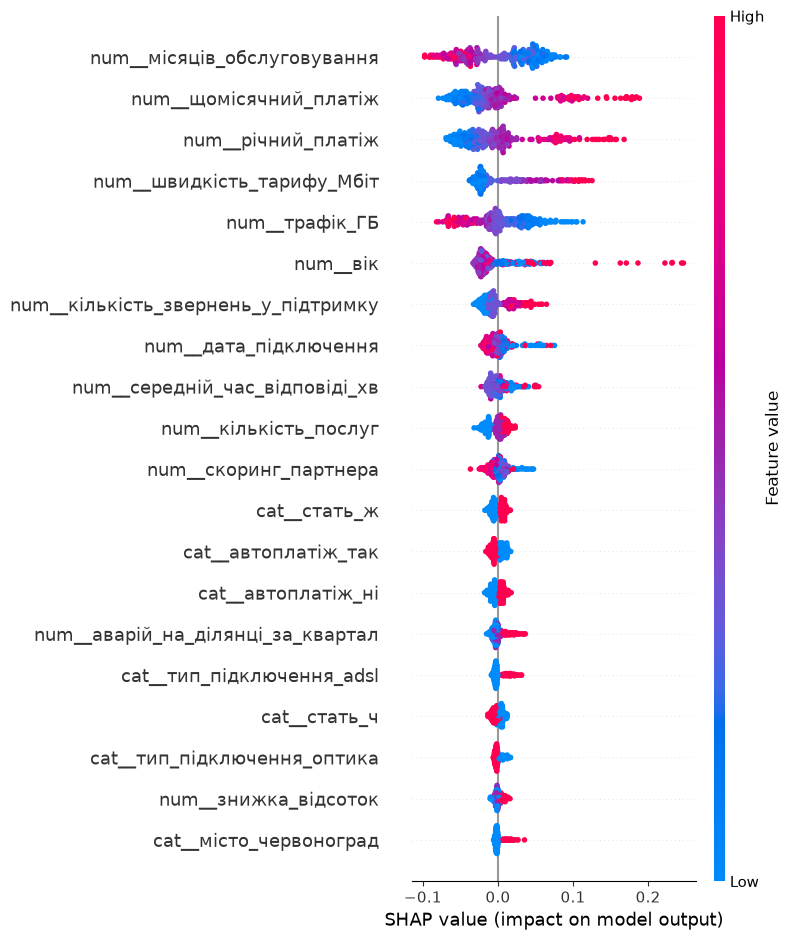

Колір показує значення, знак — напрям внеску; різні знаки для схожих кольорів указують на неоднорідність.


In [47]:
shap.summary_plot(sv1,Xte_t[:SAMPLE],feature_names=feat_names,show=False)
plt.tight_layout();plt.show()
print('Колір показує значення, знак — напрям внеску; різні знаки для схожих кольорів указують на неоднорідність.')

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [48]:
idx=int(np.argmax(model.predict_proba(Xte)[:SAMPLE,1]))
contributions=pd.Series(sv1[idx],index=mapping).groupby(level=0).sum()
top_shap=contributions.abs().nlargest(3).index
display(contributions.loc[top_shap].to_frame('внесок у ймовірність'))
pred=float(model.predict_proba(Xte)[idx,1]);shap_base=float(np.asarray(expl.expected_value)[1])
assert np.isclose(shap_base+contributions.sum(),pred,atol=1e-6)
print('Клієнт',raw.loc[Xte.index[idx],'id_клієнта'],'ризик',pred,'база',shap_base)

,внесок у ймовірність
щомісячний_платіж,0.178757
річний_платіж,0.155728
швидкість_тарифу_Мбіт,0.121164


Клієнт

 K120938 ризик 0.8233333333333334 база 0.24914682539682512


In [49]:
labels={'середній_час_відповіді_хв':'середній час очікування відповіді','місяців_обслуговування':'тривалість користування послугами','кількість_звернень_у_підтримку':'кількість звернень до підтримки','щомісячний_платіж':'щомісячна плата','річний_платіж':'річна плата','вік':'вік клієнта','знижка_відсоток':'поточна знижка'}
parts=[f"{labels.get(c,c.replace('_',' '))} {'підвищує' if contributions[c]>0 else 'знижує'} оцінку на {abs(contributions[c])*100:.1f} відсоткового пункту" for c in top_shap]
EXPLANATION_FOR_MANAGER=f'Ризик припинення договору — {pred:.1%}. Основні підказки: '+ '; '.join(parts)+'. Це статистичне пояснення; причини варто уточнити в розмові.'
print(EXPLANATION_FOR_MANAGER)

Ризик припинення договору — 82.3%. Основні підказки: щомісячна плата підвищує оцінку на 17.9 відсоткового пункту; річна плата підвищує оцінку на 15.6 відсоткового пункту; швидкість тарифу Мбіт підвищує оцінку на 12.1 відсоткового пункту. Це статистичне пояснення; причини варто уточнити в розмові.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [50]:
SHAP_NOT_CAUSAL_FEATURE=max([c for c in ['вік','місяців_обслуговування','місто','дата_підключення'] if c in contributions],key=lambda c:abs(contributions[c]))
SHAP_NOT_CAUSAL_WHY=f'Для цього клієнта внесок {contributions[SHAP_NOT_CAUSAL_FEATURE]:+.4f}; зміна запису віку, стажу, міста чи дати в CRM не змінює життєві обставини. Асоціація не доводить ефект втручання.'
print(SHAP_NOT_CAUSAL_FEATURE,SHAP_NOT_CAUSAL_WHY)

місяців_обслуговування Для цього клієнта внесок +0.0515; зміна запису віку, стажу, міста чи дати в CRM не змінює життєві обставини. Асоціація не доводить ефект втручання.


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [51]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",код_тарифного_плану,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",щомісячний_платіж + річний_платіж,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",місяців_обслуговування,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [52]:
FIFTH_MISTAKE=f'Мінімум вікового PDP {quad_center:.2f} року не означає, що треба обслуговувати лише цей вік: PDP усереднює різних клієнтів і може створювати рідкісні комбінації віку та стажу. Крім того, центр квадратної ознаки обрано після перегляду пояснень на цих даних; повторна CV після такого вибору не є незалежним доказом приросту. Потрібна нова вибірка або вкладена процедура вибору центру.'
print(FIFTH_MISTAKE)

Мінімум вікового PDP 37.54 року не означає, що треба обслуговувати лише цей вік: PDP усереднює різних клієнтів і може створювати рідкісні комбінації віку та стажу. Крім того, центр квадратної ознаки обрано після перегляду пояснень на цих даних; повторна CV після такого вибору не є незалежним доказом приросту. Потрібна нова вибірка або вкладена процедура вибору центру.


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [53]:
TOP_N=100
ranking=pd.DataFrame({'id':raw.loc[Xte.index,'id_клієнта'],'факт':yte,'ризик':model.predict_proba(Xte)[:,1]}).sort_values('ризик',ascending=False)
hits=int(ranking.head(TOP_N)['факт'].sum());random_hits=TOP_N*yte.mean();lift=(hits/TOP_N)/yte.mean()
print('Знайдено:',hits,'випадково очікували:',random_hits,'lift:',lift)

Знайдено: 56 випадково очікували: 25.0 lift: 2.24


In [54]:
LIFT_MEANING=f'У топ-100 є {hits} клієнтів із відтоком проти {random_hits:.2f} очікуваних навмання, lift={lift:.3f}; це концентрація ризику, а не кількість гарантовано врятованих договорів.'
print(LIFT_MEANING)

У топ-100 є 56 клієнтів із відтоком проти 25.00 очікуваних навмання, lift=2.240; це концентрація ризику, а не кількість гарантовано врятованих договорів.


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [ ]:
REPORT=f'''
1. ROC AUC оцінює ранжування без фіксованого порога; тривіальна accuracy={1-y.mean():.4f}, відтік={y.mean():.4f}.
2. Вилучено id_клієнта (технічний ключ при реєстрації), дату розірвання та повернення депозиту (після події), оцінку менеджера (після спостереження поведінки), філію (відома при підключенні, але артефакт). {HUMAN_LEAK_WHY}
3. Чесна базова логістична AUC={auc4.mean():.4f} ± {auc4.std():.4f} (SD згорток, не довірчий інтервал). Різниця 0.004 потребує парного інтервалу. Описова AUC лісу на відкладених 30%={auc_hold:.4f}.
4. AUC джерела={auc_src.mean():.4f} ± {auc_src.std():.4f}. {DECISION_WHY}
5. {FEATURES_VS_MODEL}
6. {FAKE_IMPORTANT}: ранг {list(gini_imp.index).index(FAKE_IMPORTANT)+1}, вбудована={gini_imp[FAKE_IMPORTANT]:.4f}, перестановочна={perm_imp[FAKE_IMPORTANT]:+.4f}. {FAKE_IMPORTANT_WHY}
7. {DUP_EXPLANATION}
8. {NONLINEAR_FEATURE}. {NONLINEAR_MEANING} Лінійний доданок не відтворює U-форму; дослідницький приріст квадрату={quad_diff[0]:+.4f} ± {quad_diff[1]:.4f}, центр={quad_center:.2f}.
9. {INTERACTION_FOUND} {BUSINESS_ACTION}
10. {SHAP_NOT_CAUSAL_FEATURE}: {SHAP_NOT_CAUSAL_WHY}
11. {LIFT_MEANING} Потрібні перевірка перенесення за філіями та A/B-тест ефекту дзвінків.

П'ята пастка: {FIFTH_MISTAKE}
Декларація про використання ШІ: Codex використано для аналізу завдання, написання коду, запуску обчислень і підготовки звіту. Автоматично перевірено виконання та узгодженість чисел. Я, студент, усе перевірив та готовий відповідати за код та результати.
'''
print(REPORT)


1. ROC AUC оцінює ранжування без фіксованого порога; тривіальна accuracy=0.7508, відтік=0.2492.
2. Вилучено id_клієнта (технічний ключ при реєстрації), дату розірвання та повернення депозиту (після події), оцінку менеджера (після спостереження поведінки), філію (відома при підключенні, але артефакт). Менеджер оцінив клієнта після спостереження подальшої поведінки; поле заповнене для всіх, тому детектор заповненості не має двох груп і не перевіряє часову доступність.
3. Чесна базова логістична AUC=0.7850 ± 0.0388 (SD згорток, не довірчий інтервал). Різниця 0.004 потребує парного інтервалу. Описова AUC лісу на відкладених 30%=0.7921.
4. AUC джерела=0.7141 ± 0.0230. Потрібен переносимий прогноз: у перших двох філіях частка відтоку стрибком вища. Вилучення філії послаблює прямий артефакт, але потрібна зовнішня перевірка за філіями та часом, бо проксі можуть залишитися.
5. Ліс дав більший середній приріст: +0.0042 ± 0.0353 проти −0.0012 ± 0.0044 для трьох нових ознак (95% парні інтервали).

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.

In [56]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)
result['розкид_чесного_AUC']=float(auc4.std())
result['звіт']=REPORT
result['порівняння_моделей']=cmp_models.reset_index().to_dict(orient='records')
result['квадратична_ознака']={'центр':quad_center,'приріст':QUAD_GAIN,'півширина_95':quad_diff[1]}
with open('lr6_результат_%02d.json'%VARIANT,'w',encoding='utf-8') as fh: json.dump(result,fh,ensure_ascii=False,indent=2)

збережено lr6_результат_12.json
